# Customer Churn Prediction
## Notebook 4: Model Evaluation

### Objective
Evaluate Logistic Regression and Decision Tree on the held-out test dataset and compare their ability to identify customers who churn.

### Evaluation Metrics
- Accuracy
- Precision
- Recall
- F1-score
- ROC-AUC
- Confusion matrix

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import joblib

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    ConfusionMatrixDisplay
)

PROJECT_DIR = Path("..")
PROCESSED_DATA_DIR = PROJECT_DIR / "data" / "processed"
MODEL_DIR = PROJECT_DIR / "models"
OUTPUT_DIR = PROJECT_DIR / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(
    PROCESSED_DATA_DIR / "customer_churn_cleaned.csv"
)

X = df.drop(columns=["Churn", "customerID"])
y = df["Churn"].map({"No": 0, "Yes": 1})

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

trained_models = {
    "Logistic Regression": joblib.load(
        MODEL_DIR / "logistic_regression.joblib"
    ),
    "Decision Tree": joblib.load(
        MODEL_DIR / "decision_tree.joblib"
    )
}

print("Test set:", X_test.shape)
print("Models loaded:", list(trained_models.keys()))

Test set: (1407, 19)
Models loaded: ['Logistic Regression', 'Decision Tree']


## 1. Model Performance Comparison

Evaluate both saved pipelines using the same test data.

Recall measures the proportion of actual churned customers correctly identified. Precision measures how many customers predicted to churn actually churned. F1-score balances precision and recall, while ROC-AUC measures how well the model ranks churned customers above non-churned customers.

In [3]:
results = []
predictions = {}

for name, model in trained_models.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    predictions[name] = y_pred

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results).set_index("Model")

display(results_df.round(3))

results_df.to_csv(OUTPUT_DIR / "model_comparison.csv")

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Model,,,,,
Logistic Regression,0.804,0.648,0.572,0.608,0.836
Decision Tree,0.733,0.499,0.799,0.615,0.818


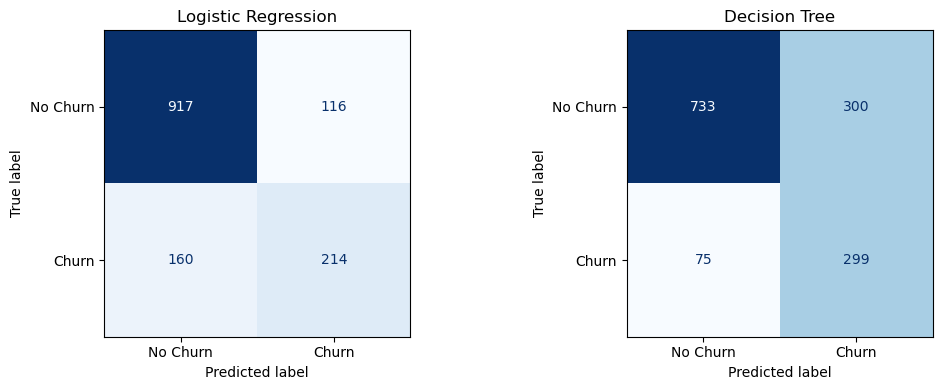

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, (name, model) in zip(axes, trained_models.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predictions[name],
        display_labels=["No Churn", "Churn"],
        cmap="Blues",
        ax=ax,
        colorbar=False
    )
    ax.set_title(name)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "confusion_matrices.png", dpi=150)
plt.show()

In [5]:
for name, y_pred in predictions.items():
    print(f"\n{name}")
    print(
        classification_report(
            y_test,
            y_pred,
            target_names=["No Churn", "Churn"],
            zero_division=0
        )
    )


Logistic Regression
              precision    recall  f1-score   support

    No Churn       0.85      0.89      0.87      1033
       Churn       0.65      0.57      0.61       374

    accuracy                           0.80      1407
   macro avg       0.75      0.73      0.74      1407
weighted avg       0.80      0.80      0.80      1407


Decision Tree
              precision    recall  f1-score   support

    No Churn       0.91      0.71      0.80      1033
       Churn       0.50      0.80      0.61       374

    accuracy                           0.73      1407
   macro avg       0.70      0.75      0.71      1407
weighted avg       0.80      0.73      0.75      1407



## 2. Conclusion

The evaluation compared Logistic Regression and Decision Tree using the same held-out test set of 1,407 customers, including 374 customers who churned.

### Key Findings

- **Logistic Regression** achieved 80.4% accuracy and an ROC-AUC of 0.836. It had higher precision (64.8%) but lower churn recall (57.2%).
- **Decision Tree** achieved 73.3% accuracy and an ROC-AUC of 0.818. It identified 79.9% of actual churned customers, but its churn precision was lower at 49.9%.
- Decision Tree achieved a slightly higher churn F1-score (61.5%) than Logistic Regression (60.8%), reflecting its stronger recall.

### Business Implications

If the primary goal is to identify as many at-risk customers as possible, Decision Tree is a promising candidate. However, its lower precision means the retention team may need to contact more customers who would not have churned.

Logistic Regression is preferable when reducing unnecessary retention outreach and obtaining stronger overall discrimination are priorities.

### Final Recommendation

Neither model is the clear winner for every business objective. Decision Tree offers higher churn recall, while Logistic Regression provides higher precision and ROC-AUC.

The final model should be selected according to the business cost of missed churn versus unnecessary retention offers. Further threshold tuning and validation could improve the balance between these outcomes.